# 19. Write a python program to implement edge detection using Sobel, Prewitt, and Canny operators.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
rows, cols = img.shape

In [3]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]])

In [4]:
sobel = np.zeros((rows, cols), dtype=np.uint8)
prewitt = np.zeros((rows, cols), dtype=np.uint8)

In [5]:
for i in range(1, rows - 1):
    for j in range(1, cols - 1):
        matrix = img[i-1:i+2, j-1:j+2]
        sx = np.sum(matrix * sobel_x)
        sy = np.sum(matrix * sobel_y)
        px = np.sum(matrix * prewitt_x)
        py = np.sum(matrix * prewitt_y)
        sobel[i][j] = min(255, (np.sqrt(sx**2 + sy**2)))
        prewitt[i][j] = min(255, (np.sqrt(px**2 + py**2)))

In [6]:
# Canny Edge Detection
canny = cv2.Canny(img, 100, 200)

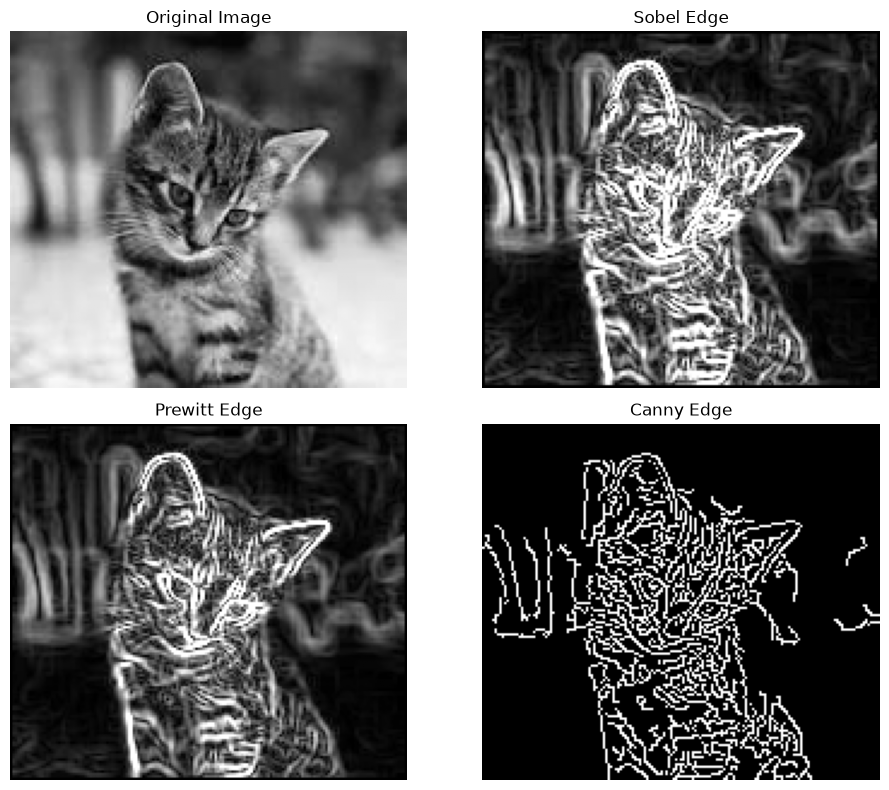

In [7]:
images = [img, sobel, prewitt, canny]

titles = ['Original Image', 'Sobel Edge',
          'Prewitt Edge', 'Canny Edge']

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

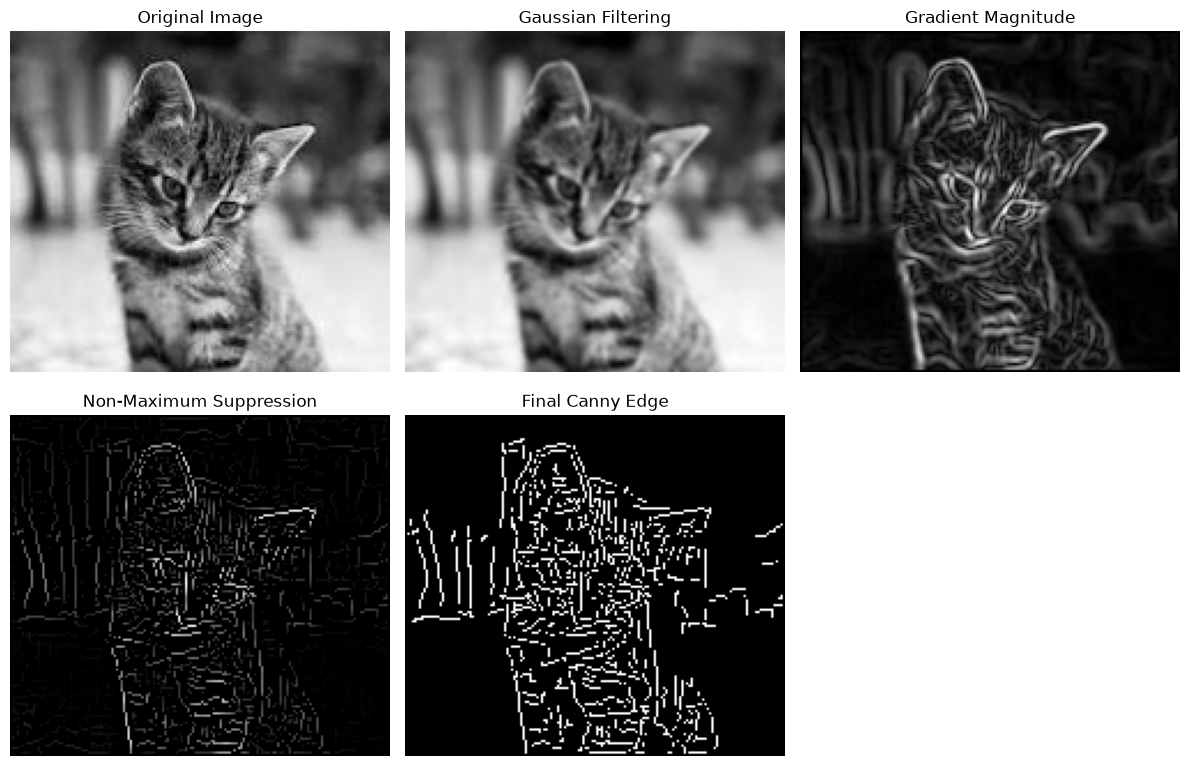

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread('image.jpeg', 0)
row, col = img.shape

# 1. Gaussian Filtering (Noise Removal)
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]) / 16

smooth = img.copy()

for i in range(1, row - 1):
    for j in range(1, col - 1):
        matrix = img[i-1:i+2, j-1:j+2]
        smooth[i, j] = np.sum(matrix * gaussian_kernel)


# 2. Gradient Calculation using Sobel Operators
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

Gx = np.zeros((row, col))
Gy = np.zeros((row, col))

for i in range(1, row - 1):
    for j in range(1, col - 1):
        matrix = smooth[i-1:i+2, j-1:j+2]
        Gx[i, j] = np.sum(matrix * sobel_x)
        Gy[i, j] = np.sum(matrix * sobel_y)

# Gradient Magnitude
magnitude = np.sqrt(Gx**2 + Gy**2)

# Normalize magnitude to 0-255
magnitude = magnitude / magnitude.max() * 255

# Gradient Direction
angle = np.arctan2(Gy, Gx) * 180 / np.pi
angle[angle < 0] += 180


# 3. Non-Maximum Suppression
nms = np.zeros((row, col))

for i in range(1, row - 1):
    for j in range(1, col - 1):

        direction = angle[i, j]
        current = magnitude[i, j]

        if (0 <= direction < 22.5) or (157.5 <= direction <= 180):
            q = magnitude[i, j+1]
            r = magnitude[i, j-1]

        elif 22.5 <= direction < 67.5:
            q = magnitude[i+1, j-1]
            r = magnitude[i-1, j+1]

        elif 67.5 <= direction < 112.5:
            q = magnitude[i+1, j]
            r = magnitude[i-1, j]

        else:
            q = magnitude[i-1, j-1]
            r = magnitude[i+1, j+1]

        if current >= q and current >= r:
            nms[i, j] = current


# 4. Double Thresholding
high_threshold = 50
low_threshold = 20

strong = 255
weak = 75

result = np.zeros((row, col), dtype=np.uint8)

strong_i, strong_j = np.where(nms >= high_threshold)
weak_i, weak_j = np.where(
    (nms >= low_threshold) & (nms < high_threshold)
)

result[strong_i, strong_j] = strong
result[weak_i, weak_j] = weak


# 5. Edge Tracking by Hysteresis
for i in range(1, row - 1):
    for j in range(1, col - 1):

        if result[i, j] == weak:

            if np.any(result[i-1:i+2, j-1:j+2] == strong):
                result[i, j] = strong
            else:
                result[i, j] = 0

# Remove remaining weak pixels
result[result == weak] = 0


# Display Results
images = [img, smooth, magnitude, nms, result]

titles = [
    'Original Image',
    'Gaussian Filtering',
    'Gradient Magnitude',
    'Non-Maximum Suppression',
    'Final Canny Edge'
]

plt.figure(figsize=(12, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()